# LeetCode #37: Sudoku Solver

https://leetcode.com/problems/sudoku-solver/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(9^m)$ | $O(m)$ |
| **Optimal: Backtracking ★** | $O(9^m)$ | $O(m)$ |

---

## Understanding the Methods

### Brute Force
Enumerate every possible assignment of digits 1–9 to all empty cells at once, then validate the completed board. This is impractical because it generates $9^{81}$ candidates before checking any constraint.

### Optimal: Backtracking ★
Find the next empty cell, try each digit 1–9 in turn, immediately check the row, column, and 3×3 box for a conflict, and recurse into the remaining empty cells. If no digit works, return false to trigger backtracking at the previous decision point.

**Why this is better than Brute Force:** Constraint checking prunes invalid branches the moment a conflict appears—long before filling the remaining cells—so the actual search space is a tiny fraction of $9^{81}$.

**Constraints:**
* board.length == 9, board[i].length == 9
* board[i][j] is a digit or '.'
* The input puzzle is guaranteed to have exactly one solution

## Solutions

### C#

In [ ]:
public class Solution {
    public void SolveSudoku(char[][] board) {
        Solve(board);
    }

    private bool Solve(char[][] board) {
        for (int row = 0; row < 9; row++) {
            for (int col = 0; col < 9; col++) {
                if (board[row][col] == '.') {
                    // Try each digit at the first empty cell found
                    for (char c = '1'; c <= '9'; c++) {
                        if (IsValid(board, row, col, c)) {
                            board[row][col] = c;
                            // If the rest of the board is solvable, we are done
                            if (Solve(board)) return true;
                            // This digit led to a dead end — undo and try the next
                            board[row][col] = '.';
                        }
                    }
                    // No digit worked at this cell: backtrack to the previous decision
                    return false;
                }
            }
        }
        // No empty cell remains — puzzle is solved
        return true;
    }

    private bool IsValid(char[][] board, int row, int col, char c) {
        for (int i = 0; i < 9; i++) {
            // Reject if the digit already appears in this row
            if (board[row][i] == c) return false;
            // Reject if the digit already appears in this column
            if (board[i][col] == c) return false;
            // Reject if the digit already appears in the 3x3 box
            int boxRow = 3 * (row / 3) + i / 3;
            int boxCol = 3 * (col / 3) + i % 3;
            if (board[boxRow][boxCol] == c) return false;
        }
        return true;
    }
}

### Python

In [ ]:
class Solution:
    def solveSudoku(self, board: list[list[str]]) -> None:
        def is_valid(row: int, col: int, c: str) -> bool:
            for i in range(9):
                # Reject if the digit already appears in this row
                if board[row][i] == c:
                    return False
                # Reject if the digit already appears in this column
                if board[i][col] == c:
                    return False
                # Reject if the digit already appears in the 3x3 box
                if board[3 * (row // 3) + i // 3][3 * (col // 3) + i % 3] == c:
                    return False
            return True

        def solve() -> bool:
            for row in range(9):
                for col in range(9):
                    if board[row][col] == '.':
                        # Try each digit at the first empty cell found
                        for c in '123456789':
                            if is_valid(row, col, c):
                                board[row][col] = c
                                # If the rest of the board is solvable, we are done
                                if solve():
                                    return True
                                # This digit led to a dead end — undo and try the next
                                board[row][col] = '.'
                        # No digit worked at this cell: backtrack to the previous decision
                        return False
            # No empty cell remains — puzzle is solved
            return True

        solve()

### Go

In [ ]:
func solveSudoku(board [][]byte) {
    solve(board)
}

func solve(board [][]byte) bool {
    for row := 0; row < 9; row++ {
        for col := 0; col < 9; col++ {
            if board[row][col] == '.' {
                // Try each digit at the first empty cell found
                for c := byte('1'); c <= '9'; c++ {
                    if isValid(board, row, col, c) {
                        board[row][col] = c
                        // If the rest of the board is solvable, we are done
                        if solve(board) {
                            return true
                        }
                        // This digit led to a dead end — undo and try the next
                        board[row][col] = '.'
                    }
                }
                // No digit worked at this cell: backtrack to the previous decision
                return false
            }
        }
    }
    // No empty cell remains — puzzle is solved
    return true
}

func isValid(board [][]byte, row, col int, c byte) bool {
    for i := 0; i < 9; i++ {
        // Reject if the digit already appears in this row
        if board[row][i] == c {
            return false
        }
        // Reject if the digit already appears in this column
        if board[i][col] == c {
            return false
        }
        // Reject if the digit already appears in the 3x3 box
        if board[3*(row/3)+i/3][3*(col/3)+i%3] == c {
            return false
        }
    }
    return true
}

### Rust

In [ ]:
impl Solution {
    pub fn solve_sudoku(board: &mut Vec<Vec<char>>) {
        Self::solve(board);
    }

    fn solve(board: &mut Vec<Vec<char>>) -> bool {
        for row in 0..9 {
            for col in 0..9 {
                if board[row][col] == '.' {
                    // Try each digit at the first empty cell found
                    for c in '1'..='9' {
                        if Self::is_valid(board, row, col, c) {
                            board[row][col] = c;
                            // If the rest of the board is solvable, we are done
                            if Self::solve(board) {
                                return true;
                            }
                            // This digit led to a dead end — undo and try the next
                            board[row][col] = '.';
                        }
                    }
                    // No digit worked at this cell: backtrack to the previous decision
                    return false;
                }
            }
        }
        // No empty cell remains — puzzle is solved
        true
    }

    fn is_valid(board: &Vec<Vec<char>>, row: usize, col: usize, c: char) -> bool {
        for i in 0..9 {
            // Reject if the digit already appears in this row
            if board[row][i] == c { return false; }
            // Reject if the digit already appears in this column
            if board[i][col] == c { return false; }
            // Reject if the digit already appears in the 3x3 box
            if board[3*(row/3)+i/3][3*(col/3)+i%3] == c { return false; }
        }
        true
    }
}

## Example Scenarios

### 1. Common Case
**Input:** The classic partially filled board (given clues in blue).
Backtracking fills each empty cell with a digit `1–9` that is legal in its row, column, and box, recursing and undoing on a dead end. The filled cells (green) complete the grid. Result: the unique solution.

### 2. Slightly Complex
**Input:** A board with a single empty cell.
The empty cell has exactly one legal candidate (a "naked single"): every other digit already appears in its row, column, or box. The solver places it without any backtracking. Result: the completed board.

### 3. Edge Case: Time Factor
**Input:** A minimal 17-clue puzzle (the fewest clues a unique Sudoku can have).
With so few constraints the search explores many branches, undoing deep guesses repeatedly. A most-constrained-cell heuristic keeps it tractable. Result: the unique solution.

### 4. Edge Case: Space Factor
**Input:** The classic board again, viewed through the recursion.
Recursion depth equals the number of empty cells (up to ~64), so the call stack is the dominant space cost; the board itself is modified in place. Result: the solution.

### 5. Almost-Impossible but Plausible
**Input:** A board with only the first row fixed to `1–9`.
Almost unconstrained, the grid admits a huge number of completions. The solver still returns the **first** valid board it reaches. Result: one legal completion.


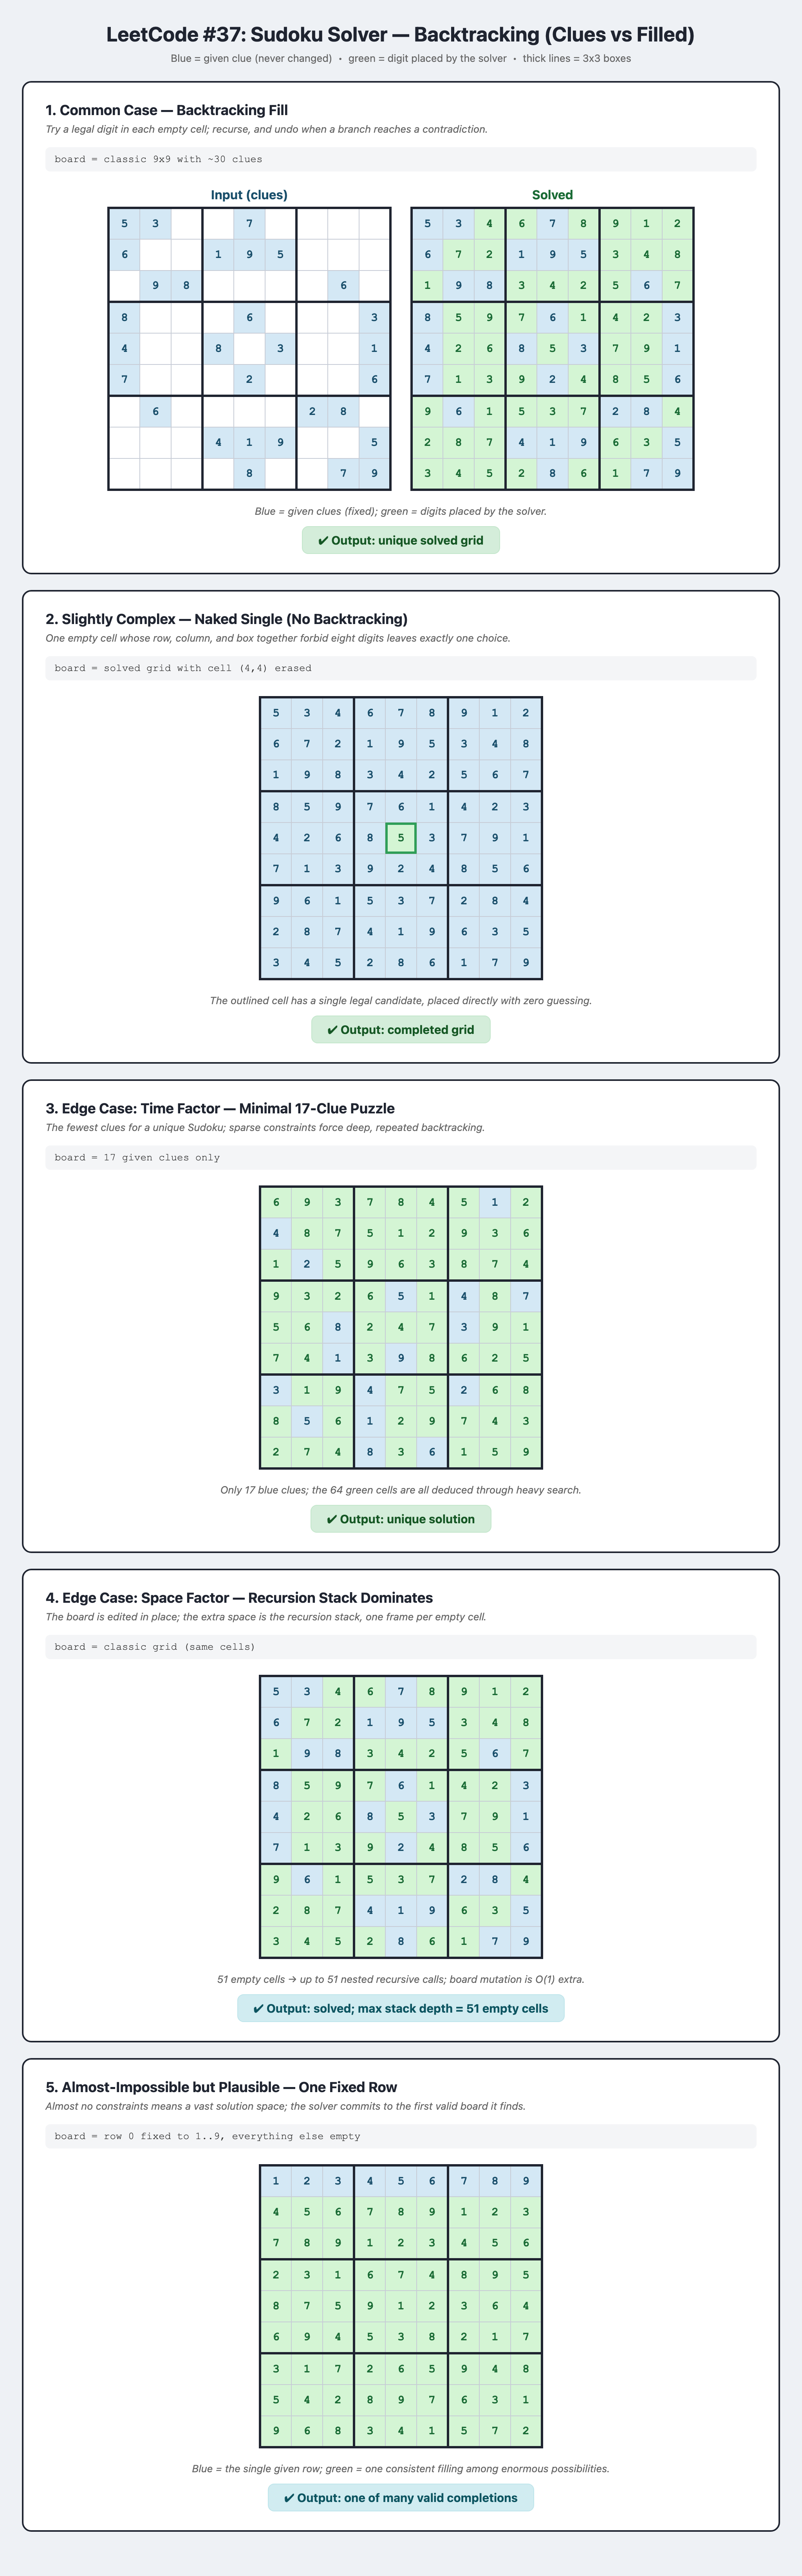